# EDA Introduction
# 📊 Exploratory Data Analysis – E-Commerce Sales Dataset
# Exploratory Data Analysis (EDA)
## E-Commerce Sales and Customer Analytics

### Introduction

Exploratory Data Analysis (EDA) is the process of examining, cleaning,
summarizing, and visualizing a dataset to understand its structure,
patterns, relationships, and important business insights.

This project analyzes a large e-commerce sales dataset containing
approximately 2.24 million order records. The dataset includes detailed
information about orders, customers, products, sales, discounts, profits,
payments, deliveries, inventory, marketing activities, and customer
behavior.

The main objective of this analysis is to understand sales performance,
profitability, customer behavior, product performance, delivery efficiency,
returns, inventory status, and the factors that influence business
performance.

### Key Areas of Analysis

The analysis focuses on the following areas:

1. Sales Performance
2. Product and Category Analysis
3. Customer Analysis
4. Profitability Analysis
5. Regional Analysis
6. Payment Method Analysis
7. Discount Analysis
8. Delivery Performance
9. Return Analysis
10. Inventory Analysis
11. Marketing and Customer Behavior
12. Time-Based Sales Trends

### Business Objectives

The main questions we aim to answer are:

- Which product categories generate the highest sales?
- Which categories generate the highest profit?
- Which products contribute the most to revenue?
- Which customer segments generate the most sales?
- Which regions perform best in terms of sales?
- Which payment methods are most commonly used?
- Does increasing discounts affect profit?
- Which shipping methods have better delivery performance?
- Which categories have the highest number of returns?
- How do sales change over time?
- What is the relationship between sales, profit, discounts, and customer behavior?
- What inventory and stock patterns can be identified?

### Dataset Features

The dataset contains information related to:

- Order and customer identification
- Order dates and delivery dates
- Product and category information
- Quantity and pricing
- Discounts, taxes, and shipping costs
- Sales and profit
- Customer age and ratings
- Returns and refund information
- Payment and shipping methods
- Customer segments and membership
- Marketing and acquisition channels
- Inventory and warehouse information
- Product characteristics
- Geographic information
- Customer behavior and website activity

### Tools Used

Python is used for the analysis with the following libraries:

- Pandas – Data manipulation and analysis
- NumPy – Numerical operations
- Matplotlib – Data visualization
- Seaborn – Statistical and attractive visualizations

### EDA Workflow

The analysis follows these steps:

1. Load the dataset
2. Understand the dataset structure
3. Check data types
4. Check missing values
5. Check duplicate records
6. Analyze categorical variables
7. Analyze numerical variables
8. Analyze sales and profit
9. Analyze customers and products
10. Analyze delivery and returns
11. Analyze time-based trends
12. Identify relationships and patterns
13. Create business-focused visualizations
14. Summarize key findings and insights

In [1]:
import pandas as pd

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_parquet(r"C:\Users\Shamm\Downloads\ecommerce_uncleaned_dataset (1).parquet")

df.head()

,order_id,customer_id,product_id,sku,order_date,ship_date,delivery_date,last_restock_date,quantity,unit_price,...,fraud_risk_level,promo_type,email_subscription,review_sentiment,customer_support_ticket,stock_location_type,product_lifecycle,bestseller_flag,eco_friendly,country_code
0,ORD00161112,CUST0342847,P052676,SKU-0022656,07 May 2022,2022-05-09,2022-05-10,NaN,4.0,21.00,...,Low,None,Unsubscribed,No Review,None,Seller Warehouse,Discontinued,N,Unknown,US
1,ORD00001370,CUST0380724,P005944,SKU-0125724,22/05/2025,2025-05-26,2025-05-31,2025-02-01,1.0,252.35,...,Low,Bundle Offer,Subscribed,positive,None,Regional Hub,Mature,No,No,IN
2,ORD00160551,CUST0356101,P025240,SKU-0565113,10-20-2022,2022-10-22,2022-11-01,NaN,10.0,733.20,...,High,BOGO,Never Opted,Positive,None,Central Warehouse,Mature,No,No,GB
3,ORD00141594,CUST0289600,P052754,SKU-0733658,10 Jul 2025,2025-07-10,2025-07-11,2025-03-30,10.0,8.14,...,Low,None,Subscribed,No Review,NaN,Seller Warehouse,Growth,No,No,SG
4,ORD00098921,CUST0526935,P003394,SKU-0089530,19 Apr 2023,2023-04-23,2023-05-04,2023-03-11,1.0,71.35,...,NaN,None,Never Opted,Positive,None,Dark Store,New Launch,Yes,No,IN


# Step 1 — Understand the dataset

In [5]:
df.shape

(2244000, 127)

In [6]:
df.columns

Index(['order_id', 'customer_id', 'product_id', 'sku', 'order_date',
       'ship_date', 'delivery_date', 'last_restock_date', 'quantity',
       'unit_price',
       ...
       'fraud_risk_level', 'promo_type', 'email_subscription',
       'review_sentiment', 'customer_support_ticket', 'stock_location_type',
       'product_lifecycle', 'bestseller_flag', 'eco_friendly', 'country_code'],
      dtype='str', length=127)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2244000 entries, 0 to 2243999
Columns: 127 entries, order_id to country_code
dtypes: float64(35), str(92)
memory usage: 3.4 GB


In [8]:
df.tail()

,order_id,customer_id,product_id,sku,order_date,ship_date,delivery_date,last_restock_date,quantity,unit_price,...,fraud_risk_level,promo_type,email_subscription,review_sentiment,customer_support_ticket,stock_location_type,product_lifecycle,bestseller_flag,eco_friendly,country_code
2243995,ORD02073350,CUST0457544,P049665,SKU-0150057,11 Apr 2025,2025-04-16,2025-04-20,2025-01-19,2.0,1637.84,...,Low,None,Unsubscribed,Positive,None,Regional Hub,Clearance,Yes,No,in
2243996,ORD02109260,CUST0429642,P027419,SKU-0054273,2024-10-04,2024-10-08,NaN,2024-08-06,2.0,46.65,...,NaN,Cashback,Subscribed,No Review,Refund Query,Seller Warehouse,New Launch,No,No,IN
2243997,ORD02050058,CUST0030666,P050328,SKU-0648104,14/04/2022,2022-04-18,2022-04-29,2022-01-03,1.0,19.18,...,Low,Flat Discount,NaN,Positive,None,Seller Warehouse,Mature,NaN,Unknown,AE
2243998,ORD02005193,CUST0105462,P041025,SKU-0607913,2024-01-17,2024-01-22,2024-01-31,2024-01-09,1.0,27.24,...,Low,Free Shipping,Subscribed,No Review,None,Seller Warehouse,New Launch,No,No,IN
2243999,ORD02128038,CUST0395943,P040250,SKU-0549162,01-27-2022,2022-01-27,2022-02-06,2021-11-28,10.0,17.34,...,Medium,None,Subscribed,Neutral,None,Regional Hub,Discontinued,N,Unknown,in


In [9]:
df.describe()

,quantity,unit_price,discount_pct,discount_amount,tax_amount,shipping_cost,total_amount,cost_price,profit,profit_margin_pct,...,cart_items_count,product_weight_kg,product_length_cm,product_width_cm,product_height_cm,coupon_value,competitor_price,conversion_rate_pct,latitude,longitude
count,2.199052e+06,2.176655e+06,2.154140e+06,2.176468e+06,2.177149e+06,2.153761e+06,2.199491e+06,2.176789e+06,2.131939e+06,2.131535e+06,...,2.131507e+06,2.108987e+06,2.109934e+06,2.109818e+06,2.109411e+06,2.130898e+06,2.019496e+06,2.064551e+06,2.019577e+06,2.019821e+06
mean,3.218061e+00,2.670157e+02,1.959700e+01,1.401305e+02,9.108097e+01,9.042103e+01,7.588802e+02,1.560082e+02,7.557094e+01,6.062245e+00,...,6.003821e+00,1.498479e+00,6.249345e+01,4.248765e+01,3.099759e+01,1.215888e+02,2.230063e+02,4.763697e+00,1.000772e+01,1.504761e+01
std,2.751530e+00,1.888260e+03,1.633745e+01,4.241386e+02,2.431132e+02,8.320007e+01,1.556766e+03,2.530024e+02,3.889338e+02,1.750067e+01,...,3.162084e+00,1.671978e+00,3.319471e+01,2.164301e+01,1.673445e+01,1.687829e+02,3.585066e+02,3.252349e+00,2.597604e+01,7.793946e+01
min,-1.000000e+01,7.500000e-01,0.000000e+00,0.000000e+00,4.000000e-02,0.000000e+00,-1.649925e+04,4.400000e-01,-1.741955e+04,-7.608000e+01,...,1.000000e+00,1.000000e-02,5.000000e+00,5.000000e+00,2.000000e+00,0.000000e+00,6.900000e-01,0.000000e+00,-3.499990e+01,-1.199999e+02
25%,1.000000e+00,4.554000e+01,5.000000e+00,4.040000e+00,8.470000e+00,8.740000e+00,1.681900e+02,3.106000e+01,-3.790000e+00,-2.090000e+00,...,3.000000e+00,5.400000e-01,3.370000e+01,2.380000e+01,1.650000e+01,0.000000e+00,4.491000e+01,2.350000e+00,-1.248210e+01,-5.258330e+01
50%,2.000000e+00,9.939000e+01,2.000000e+01,2.849000e+01,2.505000e+01,6.504000e+01,3.260800e+02,6.855000e+01,1.508000e+01,7.070000e+00,...,6.000000e+00,1.000000e+00,6.250000e+01,4.250000e+01,3.100000e+01,5.000000e+01,9.855000e+01,4.060000e+00,1.000103e+01,1.509568e+01
75%,4.000000e+00,2.364900e+02,3.000000e+01,1.074600e+02,7.622000e+01,1.515500e+02,7.086000e+02,1.638200e+02,7.349000e+01,1.749000e+01,...,9.000000e+00,1.830000e+00,9.130000e+01,6.120000e+01,4.550000e+01,2.000000e+02,2.346200e+02,6.430000e+00,3.249145e+01,8.254120e+01
max,1.000000e+01,4.609800e+05,1.500000e+02,3.113045e+04,1.782625e+04,2.590000e+02,9.821593e+04,1.230888e+04,2.371433e+04,4.758000e+01,...,1.100000e+01,7.062000e+01,1.200000e+02,8.000000e+01,6.000000e+01,5.000000e+02,1.788281e+04,3.470000e+01,5.499997e+01,1.499999e+02


# Step 2 — Check missing values

In [10]:
df.isnull().sum()

order_id                    0
customer_id                 0
product_id                  0
sku                         0
order_date              22253
                        ...  
stock_location_type     67102
product_lifecycle      111714
bestseller_flag         90068
eco_friendly           111998
country_code            67460
Length: 127, dtype: int64

In [11]:
missing = df.isnull().sum()

missing_percent = (missing / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing": missing,
    "Percentage": missing_percent
})

missing_df.sort_values("Percentage", ascending=False)

,Missing,Percentage
cancellation_reason,2064213,91.988102
refund_method,2019870,90.012032
return_reason,2019293,89.986319
coupon_code,1571584,70.034938
rating_band,560386,24.972638
...,...,...
sku,0,0.000000
product_id,0,0.000000
customer_id,0,0.000000
order_id,0,0.000000


# Step 3 — Check duplicate records

In [12]:
df.duplicated().sum()(##there is no duplicate)

np.int64(0)

In [15]:
df["order_id"].duplicated().sum()

np.int64(44000)

In [16]:
df["customer_id"].duplicated().sum()

np.int64(1659374)

In [17]:
df["product_id"].duplicated().sum()

np.int64(2184001)

# Step 4 — Categorical analysis

In [18]:
df["customer_gender"].value_counts()

customer_gender
Male                 631952
Female               591728
M                    211073
F                    210936
female               126757
male                 125946
Prefer not to say    105794
Other                104692
Name: count, dtype: int64

In [19]:
df["customer_gender"].value_counts()

customer_gender
Male                 631952
Female               591728
M                    211073
F                    210936
female               126757
male                 125946
Prefer not to say    105794
Other                104692
Name: count, dtype: int64

In [20]:
df["category"].value_counts()

category
Electronics         412922
Fashion             392241
Home & Kitchen      248303
Automotive          206828
Grocery             186421
Beauty              186230
Sports              165015
Toys                144400
Books               124753
 Electronics          6739
Electronics           6627
electronics           6562
ELECTRONICS           6491
fashion               6315
FASHION               6283
Fashion               6197
 Fashion              6168
 Home & Kitchen       4078
HOME & KITCHEN        3999
Home & Kitchen        3951
home & kitchen        3882
automotive            3395
Automotive            3244
AUTOMOTIVE            3206
 Automotive           3203
 Beauty               3098
Grocery               3068
grocery               3045
 Grocery              3027
beauty                2961
GROCERY               2945
BEAUTY                2917
Beauty                2902
SPORTS                2752
sports                2649
Sports                2616
 Sports            

In [22]:
df["sub_category"].value_counts()

sub_category
Mobile Phones       68248
Bike Accessories    68217
Tools               68206
Tablets             68191
Cameras             68127
                    ...  
academic              458
non-fiction           458
Comics                453
 Comics               453
Non-Fiction           452
Name: count, Length: 200, dtype: int64

In [23]:
df["payment_method"].value_counts()

payment_method
UPI                   630342
Credit Card           413381
Cash on Delivery      351610
Debit Card            309825
Net Banking           165276
EMI                   104839
Wallet                103107
UPI                     9968
 UPI                    9868
upi                     9800
 Credit Card            6722
CREDIT CARD             6558
credit card             6536
Credit Card             6490
Cash on Delivery        5676
 Cash on Delivery       5662
CASH ON DELIVERY        5620
cash on delivery        5583
DEBIT CARD              5002
Debit Card              4952
debit card              4927
 Debit Card             4854
Net Banking             2715
net banking             2692
 Net Banking            2630
NET BANKING             2623
EMI                     1699
emi                     1686
 EMI                    1684
 Wallet                 1670
wallet                  1605
Wallet                  1576
WALLET                  1572
Name: count, dtype: int64

In [24]:
df["payment_method"].value_counts()

payment_method
UPI                   630342
Credit Card           413381
Cash on Delivery      351610
Debit Card            309825
Net Banking           165276
EMI                   104839
Wallet                103107
UPI                     9968
 UPI                    9868
upi                     9800
 Credit Card            6722
CREDIT CARD             6558
credit card             6536
Credit Card             6490
Cash on Delivery        5676
 Cash on Delivery       5662
CASH ON DELIVERY        5620
cash on delivery        5583
DEBIT CARD              5002
Debit Card              4952
debit card              4927
 Debit Card             4854
Net Banking             2715
net banking             2692
 Net Banking            2630
NET BANKING             2623
EMI                     1699
emi                     1686
 EMI                    1684
 Wallet                 1670
wallet                  1605
Wallet                  1576
WALLET                  1572
Name: count, dtype: int64

In [25]:
df["order_status"].value_counts()

order_status
Delivered       1420459
Shipped          166975
Returned         146247
Cancelled        145693
Processing       104856
Pending          104186
Delivered         22849
DELIVERED         22811
delivered         22726
 Delivered        22691
Shipped            2684
shipped            2658
 Shipped           2625
SHIPPED            2540
cancelled          2400
 Cancelled         2391
returned           2337
RETURNED           2320
Cancelled          2317
 Returned          2317
CANCELLED          2286
Returned           2270
pending            1745
Pending            1663
 Pending           1648
 Processing        1628
processing         1609
PENDING            1604
Processing         1596
PROCESSING         1587
Name: count, dtype: int64

In [26]:
df["region"].value_counts()

region
South              626650
West               417563
North              376929
International      312765
East               209120
Central            146225
South                6536
 South               6531
SOUTH                6436
south                6384
West                 4564
west                 4466
WEST                 4426
 West                4395
north                3948
NORTH                3884
 North               3876
North                3855
international        3334
 International       3287
International        3189
INTERNATIONAL        3170
east                 2194
 East                2189
EAST                 2188
East                 2065
 Central             1563
central              1539
Central              1509
CENTRAL              1502
Name: count, dtype: int64

In [27]:
df["sales_channel"].value_counts()

sales_channel
Mobile App           722736
Website              620115
Marketplace          414825
Social Commerce      206443
Retail Store         103053
Mobile App            11687
mobile app            11538
 Mobile App           11377
MOBILE APP            11372
website                9994
Website                9985
 Website               9846
WEBSITE                9788
marketplace            6667
 Marketplace           6629
MARKETPLACE            6566
Marketplace            6550
Social Commerce        3360
SOCIAL COMMERCE        3335
 Social Commerce       3308
social commerce        3307
Retail Store           1689
 Retail Store          1673
retail store           1650
RETAIL STORE           1638
Name: count, dtype: int64

# Step 5 — Numerical analysis

In [28]:
df[
    [
        "quantity",
        "unit_price",
        "discount_pct",
        "total_amount",
        "profit",
        "profit_margin_pct"
    ]
].describe()

,quantity,unit_price,discount_pct,total_amount,profit,profit_margin_pct
count,2.199052e+06,2.176655e+06,2.154140e+06,2.199491e+06,2.131939e+06,2.131535e+06
mean,3.218061e+00,2.670157e+02,1.959700e+01,7.588802e+02,7.557094e+01,6.062245e+00
std,2.751530e+00,1.888260e+03,1.633745e+01,1.556766e+03,3.889338e+02,1.750067e+01
min,-1.000000e+01,7.500000e-01,0.000000e+00,-1.649925e+04,-1.741955e+04,-7.608000e+01
25%,1.000000e+00,4.554000e+01,5.000000e+00,1.681900e+02,-3.790000e+00,-2.090000e+00
50%,2.000000e+00,9.939000e+01,2.000000e+01,3.260800e+02,1.508000e+01,7.070000e+00
75%,4.000000e+00,2.364900e+02,3.000000e+01,7.086000e+02,7.349000e+01,1.749000e+01
max,1.000000e+01,4.609800e+05,1.500000e+02,9.821593e+04,2.371433e+04,4.758000e+01


# Step 6 — Sales analysis

In [29]:
df["total_amount"].sum()

np.float64(1669150199.01)

In [30]:
df["total_amount"].mean()

np.float64(758.8802131993266)

In [31]:
df["total_amount"].max()

np.float64(98215.93)

In [32]:
df["total_amount"].min()

np.float64(-16499.25)

In [33]:
df["profit"].sum()

np.float64(161112638.66)

# Step 7 — Category vs Sales

In [34]:
category_sales = (
    df.groupby("category")["total_amount"]
    .sum()
    .sort_values(ascending=False)
)

category_sales

category
Electronics         8.785301e+08
Fashion             1.809795e+08
Home & Kitchen      1.600489e+08
Automotive          8.785878e+07
Sports              8.280531e+07
Beauty              5.099272e+07
Toys                4.205089e+07
Grocery             2.698001e+07
Books               2.650107e+07
 Electronics        1.450465e+07
electronics         1.445123e+07
Electronics         1.438840e+07
ELECTRONICS         1.399169e+07
fashion             2.933909e+06
 Fashion            2.916064e+06
FASHION             2.897959e+06
Fashion             2.839457e+06
 Home & Kitchen     2.646135e+06
HOME & KITCHEN      2.599362e+06
home & kitchen      2.455029e+06
Home & Kitchen      2.443578e+06
Automotive          1.374417e+06
automotive          1.373703e+06
 Automotive         1.363919e+06
AUTOMOTIVE          1.358396e+06
SPORTS              1.356400e+06
 Sports             1.348007e+06
sports              1.302799e+06
Sports              1.285331e+06
 Beauty             8.716645e+05
B

In [35]:
category_profit = (
    df.groupby("category")["profit"]
    .sum()
    .sort_values(ascending=False)
)

category_profit

category
Electronics         92385889.20
Fashion             15929778.60
Home & Kitchen      15074772.07
Automotive           7612703.79
Sports               7515824.55
Beauty               3801667.35
Toys                 3181990.36
Books                1691967.46
Electronics          1586603.58
electronics          1516944.47
ELECTRONICS          1418100.02
 Electronics         1393019.35
Grocery              1155242.25
fashion               283068.66
FASHION               266937.29
 Home & Kitchen       260316.80
Fashion               259064.52
 Fashion              258764.83
HOME & KITCHEN        248521.58
home & kitchen        227501.51
Home & Kitchen        200150.85
SPORTS                128001.76
AUTOMOTIVE            123700.48
 Sports               120976.24
 Automotive           118829.62
Sports                117334.54
automotive            116261.52
Automotive            115666.85
sports                109652.25
Beauty                 67267.17
BEAUTY                 66192.19

# Step 8 — Region analysis

In [36]:
region_sales = (
    df.groupby("region")["total_amount"]
    .sum()
    .sort_values(ascending=False)
)

region_sales

region
South              4.653487e+08
West               3.097847e+08
North              2.807896e+08
International      2.325454e+08
East               1.556032e+08
Central            1.095772e+08
South              5.142236e+06
 South             4.827965e+06
SOUTH              4.684845e+06
south              4.620480e+06
WEST               3.475990e+06
 West              3.401968e+06
West               3.393291e+06
west               3.244383e+06
north              3.065236e+06
 North             2.907337e+06
North              2.877363e+06
NORTH              2.838766e+06
international      2.467916e+06
International      2.394399e+06
INTERNATIONAL      2.361839e+06
 International     2.321133e+06
East               1.687891e+06
east               1.647425e+06
 East              1.633416e+06
EAST               1.603473e+06
central            1.157178e+06
CENTRAL            1.127266e+06
 Central           1.092777e+06
Central            1.047173e+06
Name: total_amount, dtype: float6

In [37]:
region_profit = (
    df.groupby("region")["profit"]
    .sum()
    .sort_values(ascending=False)
)

region_profit

region
South              44705744.78
West               30018568.22
North              27084733.14
International      22422169.88
East               15174261.84
Central            10615399.27
South                542990.74
south                477353.56
 South               442879.02
SOUTH                436815.97
WEST                 344578.08
West                 338841.67
 West                332349.19
west                 308050.58
NORTH                300102.73
north                298852.94
 North               298082.36
North                282250.62
international        245338.06
International        244507.91
 International       223911.23
INTERNATIONAL        198011.39
EAST                 158052.74
 East                147788.07
east                 147153.13
East                 127678.10
central              110730.02
CENTRAL              107660.28
Central              103452.92
 Central              93565.15
Name: profit, dtype: float64

# Step 9 — Customer analysis

In [38]:
#Customer type
df["customer_type"].value_counts()

customer_type
B2C             1478398
B2B              211201
Business         208808
Individual       104871
B2C              104861
 B2C              15243
B2C               15242
b2c               15111
Business           2275
 B2B               2210
BUSINESS           2189
business           2176
 Business          2167
B2B                2157
b2b                2149
 Individual        1129
INDIVIDUAL         1119
B2C                1116
 B2C               1103
Individual         1085
individual         1071
b2c                1046
Name: count, dtype: int64

In [39]:
#Customer type vs sales
df.groupby("customer_type")["total_amount"].sum().sort_values(ascending=False)

customer_type
B2C             1.100274e+09
B2B             1.565209e+08
Business        1.539602e+08
Individual      7.874727e+07
B2C             7.816899e+07
B2C             1.174037e+07
 B2C            1.142147e+07
b2c             1.124163e+07
business        1.803057e+06
 B2B            1.737444e+06
BUSINESS        1.651661e+06
 Business       1.631611e+06
b2b             1.614766e+06
B2B             1.547602e+06
Business        1.523923e+06
B2C             8.809688e+05
individual      8.520878e+05
 B2C            8.464651e+05
 Individual     8.334076e+05
INDIVIDUAL      8.116449e+05
Individual      7.271616e+05
b2c             7.140610e+05
Name: total_amount, dtype: float64

In [40]:
#Loyalty tier
df.groupby("customer_type")["total_amount"].sum().sort_values(ascending=False)

customer_type
B2C             1.100274e+09
B2B             1.565209e+08
Business        1.539602e+08
Individual      7.874727e+07
B2C             7.816899e+07
B2C             1.174037e+07
 B2C            1.142147e+07
b2c             1.124163e+07
business        1.803057e+06
 B2B            1.737444e+06
BUSINESS        1.651661e+06
 Business       1.631611e+06
b2b             1.614766e+06
B2B             1.547602e+06
Business        1.523923e+06
B2C             8.809688e+05
individual      8.520878e+05
 B2C            8.464651e+05
 Individual     8.334076e+05
INDIVIDUAL      8.116449e+05
Individual      7.271616e+05
b2c             7.140610e+05
Name: total_amount, dtype: float64

# Step 10 — Product analysis

In [41]:
top_products = (
    df.groupby("product_id")["total_amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

product_id
P000167    133910.57
P028072    119653.76
P037693    117754.55
P031623    113386.68
P048435    112973.03
P056689    112329.37
P008966    107909.65
P044575    101646.87
P053185    100606.36
P046773    100588.53
Name: total_amount, dtype: float64

In [42]:
#Top brands
top_brands = (
    df.groupby("brand")["total_amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_brands

brand
HP             76175043.61
LG             75354477.51
Nike           75118127.95
Samsung        75111164.01
Lenovo         74865542.16
Decathlon      74825030.56
Prestige       74793505.52
Lakme          74761382.15
Local Brand    74747868.87
Adidas         74711134.90
Name: total_amount, dtype: float64

 # Step 11 — Payment analysis

In [43]:
payment_sales = (
    df.groupby("payment_method")["total_amount"]
    .sum()
    .sort_values(ascending=False)
)

payment_sales

payment_method
UPI                   4.700450e+08
Credit Card           3.070212e+08
Cash on Delivery      2.618760e+08
Debit Card            2.296603e+08
Net Banking           1.217807e+08
EMI                   7.787341e+07
Wallet                7.638655e+07
upi                   7.531981e+06
UPI                   7.511156e+06
 UPI                  7.270018e+06
 Credit Card          5.456820e+06
credit card           5.121085e+06
CREDIT CARD           5.026496e+06
Credit Card           4.878832e+06
cash on delivery      4.352168e+06
Cash on Delivery      4.170665e+06
CASH ON DELIVERY      4.127490e+06
 Cash on Delivery     4.102020e+06
Debit Card            3.779520e+06
debit card            3.695286e+06
DEBIT CARD            3.672748e+06
 Debit Card           3.478922e+06
net banking           2.041994e+06
Net Banking           2.000067e+06
NET BANKING           1.941281e+06
 Net Banking          1.874918e+06
 Wallet               1.375363e+06
 EMI                  1.307438e+06
walle

In [44]:
#Count transactions:
df["payment_method"].value_counts()

payment_method
UPI                   630342
Credit Card           413381
Cash on Delivery      351610
Debit Card            309825
Net Banking           165276
EMI                   104839
Wallet                103107
UPI                     9968
 UPI                    9868
upi                     9800
 Credit Card            6722
CREDIT CARD             6558
credit card             6536
Credit Card             6490
Cash on Delivery        5676
 Cash on Delivery       5662
CASH ON DELIVERY        5620
cash on delivery        5583
DEBIT CARD              5002
Debit Card              4952
debit card              4927
 Debit Card             4854
Net Banking             2715
net banking             2692
 Net Banking            2630
NET BANKING             2623
EMI                     1699
emi                     1686
 EMI                    1684
 Wallet                 1670
wallet                  1605
Wallet                  1576
WALLET                  1572
Name: count, dtype: int64

# Step 12 — Discount analysis

In [45]:
df.groupby("discount_band")["total_amount"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
discount_band,,,
High (26-40%),421964,2.655690e+08,629.364106
Low (1-10%),422659,3.622324e+08,857.032252
Medium (11-25%),632847,4.778211e+08,755.034211
Mega (>40%),212737,1.078638e+08,507.028920
No Discount,421205,3.886380e+08,922.681273


In [46]:
#Then investigate whether discounts affect profit:
df.groupby("discount_band")["profit"].mean().sort_values(ascending=False)

discount_band
No Discount        216.209891
Low (1-10%)        161.092910
Medium (11-25%)     72.003581
High (26-40%)      -35.449398
Mega (>40%)       -141.148088
Name: profit, dtype: float64

# Step 13 — Return analysis

In [47]:
df["is_returned"].value_counts()

is_returned
No     1849706
yes     109120
Yes     108971
no      108612
Name: count, dtype: int64

In [48]:
df["return_reason"].value_counts()

return_reason
Not as Described    32312
Changed Mind        32209
Damaged             32157
Size Issue          32085
Quality Issue       32071
Wrong Item          32020
Late Delivery       31853
Name: count, dtype: int64

In [49]:
df["return_qty"].sum()

np.float64(151848.0)

In [50]:
df.groupby("category")["return_qty"].sum().sort_values(ascending=False)

category
Electronics         28207.0
Fashion             26582.0
Home & Kitchen      16633.0
Automotive          13900.0
Beauty              12641.0
Grocery             12637.0
Sports              11072.0
Toys                 9729.0
Books                8468.0
 Electronics          487.0
Electronics           458.0
ELECTRONICS           443.0
FASHION               443.0
fashion               432.0
electronics           423.0
Fashion               413.0
 Fashion              410.0
HOME & KITCHEN        277.0
home & kitchen        276.0
 Home & Kitchen       264.0
Home & Kitchen        255.0
automotive            233.0
Beauty                232.0
 Automotive           222.0
AUTOMOTIVE            219.0
Automotive            209.0
BEAUTY                204.0
 Grocery              201.0
 Beauty               197.0
beauty                197.0
GROCERY               194.0
Grocery               185.0
sports                182.0
SPORTS                177.0
grocery               176.0
 Sports    

# Step 14 — Delivery analysis

In [51]:
#Average delivery time:
df["delivery_days"].mean()

np.float64(10.007356577975319)

In [52]:
#Delivery speed:
df["delivery_speed"].value_counts()

delivery_speed
Slow (8-12d)        737582
Very Slow (13d+)    664578
Normal (4-7d)       515078
Fast (1-3d)         147037
Name: count, dtype: int64

In [53]:
#Average delivery days by shipping method:
df.groupby("shipping_method")["delivery_days"].mean().sort_values()

shipping_method
 Pickup        9.780795
 Economy       9.933933
Pickup         9.942282
pickup         9.948133
 Same Day      9.954821
STANDARD       9.967354
EXPRESS        9.974474
ECONOMY        9.974537
standard       9.979296
Economy        9.990491
Pickup         9.998987
Economy       10.004888
Express       10.005977
Standard      10.006306
 Standard     10.015094
economy       10.018355
Same Day      10.020519
Express       10.037995
Standard      10.048169
same day      10.054001
PICKUP        10.066396
express       10.073933
 Express      10.111818
SAME DAY      10.159836
Same Day      10.276190
Name: delivery_days, dtype: float64

# Step 15 — Inventory analysis

In [54]:
# Check stock status:
df["stock_status"].value_counts()

stock_status
Overstock       1594409
In Stock         480472
Low Stock         53438
Invalid            2131
Out of Stock       1067
Name: count, dtype: int64

In [55]:
#Stock by category:
df.groupby("category")["stock_on_hand"].sum().sort_values(ascending=False)

category
Electronics         390971346.0
Fashion             370888304.0
Home & Kitchen      235530628.0
Automotive          196178536.0
Grocery             176619741.0
Beauty              176210496.0
Sports              155628546.0
Toys                136700660.0
Books               117973547.0
 Electronics          6348418.0
Electronics           6301985.0
electronics           6202341.0
ELECTRONICS           6101131.0
fashion               5972900.0
Fashion               5928773.0
FASHION               5870141.0
 Fashion              5838909.0
 Home & Kitchen       3914535.0
HOME & KITCHEN        3745494.0
Home & Kitchen        3725871.0
home & kitchen        3725467.0
automotive            3159537.0
Automotive            3057398.0
AUTOMOTIVE            3037586.0
 Automotive           3026102.0
 Beauty               2952233.0
Grocery               2937111.0
grocery               2844019.0
GROCERY               2816943.0
beauty                2801007.0
Beauty                2770865.0

In [56]:
#Reorder analysis:
df[df["stock_on_hand"] < df["reorder_level"]][
    ["product_id", "stock_on_hand", "reorder_level", "reorder_qty"]
].head(20)

,product_id,stock_on_hand,reorder_level,reorder_qty
1,P005944,134.0,150.0,200.0
17,P029632,36.0,200.0,1000.0
55,P006585,-1950.0,50.0,200.0
58,P055007,45.0,200.0,1000.0
65,P018904,112.0,200.0,100.0
68,P003614,20.0,200.0,500.0
83,P004673,65.0,100.0,200.0
107,P006977,19.0,50.0,1000.0
116,P027337,89.0,150.0,500.0
153,P014118,13.0,100.0,1000.0


# Step 16 — Marketing analysis

In [57]:
#Marketing spend:
df["marketing_spend"].sum()

np.float64(63252536.97)

In [58]:
#Sales by acquisition channel:
df.groupby("acquisition_channel")["total_amount"].sum().sort_values(ascending=False)

acquisition_channel
Google Ads           1.895699e+08
SEO                  1.891180e+08
Friend Referral      1.888662e+08
Offline Event        1.887603e+08
Newsletter           1.886227e+08
Instagram            1.880322e+08
Facebook             1.878991e+08
YouTube              1.866906e+08
 Offline Event       2.188715e+06
FACEBOOK             2.185554e+06
FRIEND REFERRAL      2.109677e+06
youtube              2.082035e+06
 Instagram           2.073508e+06
YouTube              2.066897e+06
 SEO                 2.059125e+06
seo                  2.032807e+06
google ads           2.032431e+06
OFFLINE EVENT        2.029309e+06
friend referral      2.022183e+06
 Friend Referral     2.015433e+06
Google Ads           2.002916e+06
NEWSLETTER           1.992180e+06
SEO                  1.979182e+06
Offline Event        1.967540e+06
YOUTUBE              1.966420e+06
 Newsletter          1.965256e+06
INSTAGRAM            1.965203e+06
Newsletter           1.964302e+06
Instagram            1.96183

In [59]:
#Campaign performance:
df.groupby("campaign_name")["total_amount"].sum().sort_values(ascending=False).head(10)

campaign_name
No Campaign       4.888617e+08
Summer Sale       1.836707e+08
Black Friday      1.530547e+08
New Year Bash     1.525905e+08
Diwali Dhamaka    1.519612e+08
Monsoon Offer     1.514105e+08
Big Billion       1.211896e+08
Republic Day      1.204471e+08
NO CAMPAIGN       5.252618e+06
No Campaign       4.900405e+06
Name: total_amount, dtype: float64

# Step 17 — Time-series analysis

In [60]:
#Sales by year
df.groupby("order_year")["total_amount"].sum()

order_year
2022    4.390961e+08
2023    4.402031e+08
2024    4.427968e+08
2025    3.305386e+08
Name: total_amount, dtype: float64

In [61]:
#Sales by month
df.groupby("order_month")["total_amount"].sum()

order_month
April        1.458221e+08
August       1.497143e+08
December     1.107251e+08
February     1.363228e+08
January      1.492059e+08
July         1.494782e+08
June         1.461749e+08
March        1.504829e+08
May          1.495145e+08
November     1.075669e+08
October      1.135354e+08
September    1.440916e+08
Name: total_amount, dtype: float64

In [62]:
#Sales by weekday
df.groupby("order_weekday")["total_amount"].sum()

order_weekday
Friday       2.370086e+08
Monday       2.347426e+08
Saturday     2.364454e+08
Sunday       2.370601e+08
Thursday     2.340959e+08
Tuesday      2.375655e+08
Wednesday    2.357164e+08
Name: total_amount, dtype: float64

# Step 18 — Visualization

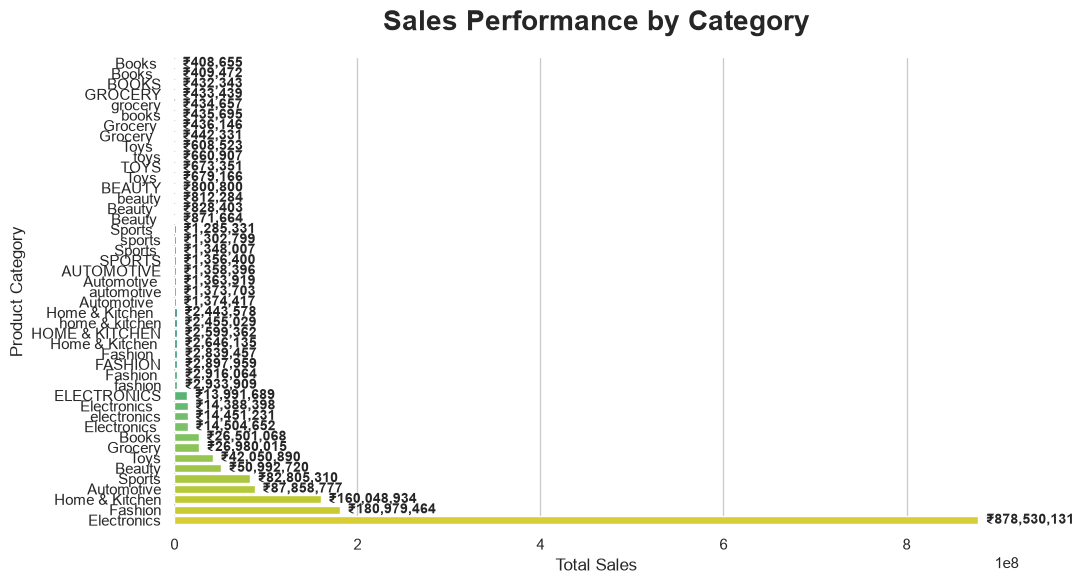

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

category_sales = (
    df.groupby("category")["total_amount"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=category_sales.values,
    y=category_sales.index,
    hue=category_sales.index,
    palette="viridis",
    legend=False
)

plt.title("Sales Performance by Category",
          fontsize=20, fontweight="bold", pad=20)

plt.xlabel("Total Sales", fontsize=12)
plt.ylabel("Product Category", fontsize=12)

for i, value in enumerate(category_sales.values):
    ax.text(value, i, f"  ₹{value:,.0f}",
            va="center", fontsize=10, fontweight="bold")

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

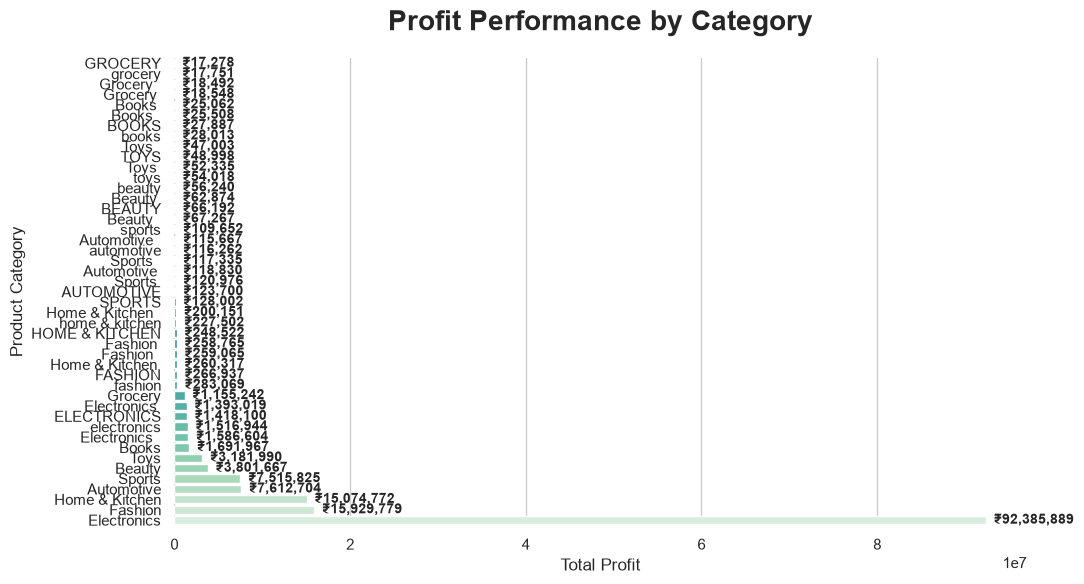

In [76]:
#2. Profit by Category
category_profit = (
    df.groupby("category")["profit"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=category_profit.values,
    y=category_profit.index,
    hue=category_profit.index,
    palette="mako",
    legend=False
)

plt.title("Profit Performance by Category",
          fontsize=20, fontweight="bold", pad=20)

plt.xlabel("Total Profit", fontsize=12)
plt.ylabel("Product Category", fontsize=12)

for i, value in enumerate(category_profit.values):
    ax.text(value, i, f"  ₹{value:,.0f}",
            va="center", fontsize=10, fontweight="bold")

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

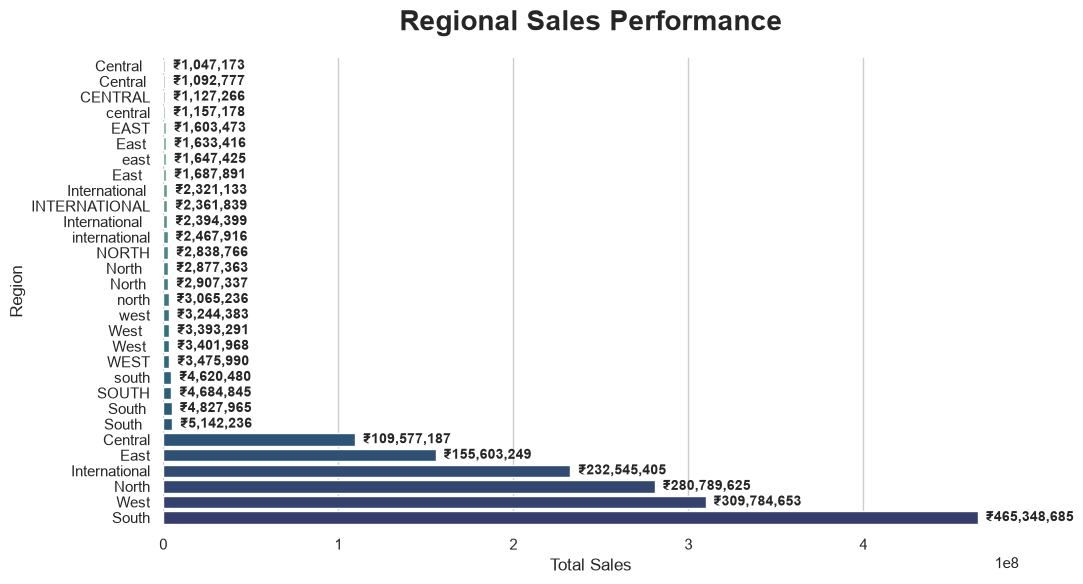

In [77]:
#3. Sales by Region
region_sales = (
    df.groupby("region")["total_amount"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=region_sales.values,
    y=region_sales.index,
    hue=region_sales.index,
    palette="crest",
    legend=False
)

plt.title("Regional Sales Performance",
          fontsize=20, fontweight="bold", pad=20)

plt.xlabel("Total Sales", fontsize=12)
plt.ylabel("Region", fontsize=12)

for i, value in enumerate(region_sales.values):
    ax.text(value, i, f"  ₹{value:,.0f}",
            va="center", fontsize=10, fontweight="bold")

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

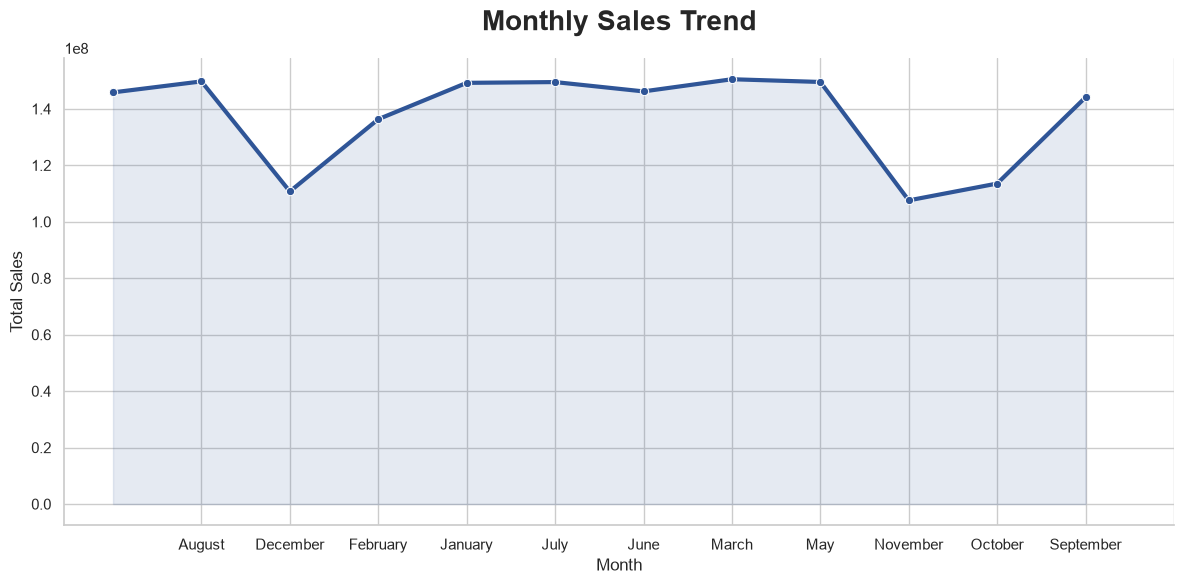

In [78]:
#4. Monthly Sales Trend
monthly_sales = (
    df.groupby("order_month")["total_amount"]
    .sum()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker="o",
    linewidth=3,
    color="#2F5597"
)

plt.fill_between(
    monthly_sales.index,
    monthly_sales.values,
    alpha=0.12,
    color="#2F5597"
)

plt.title("Monthly Sales Trend",
          fontsize=20, fontweight="bold", pad=20)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)

plt.xticks(range(1, 13))

sns.despine()
plt.tight_layout()
plt.show()

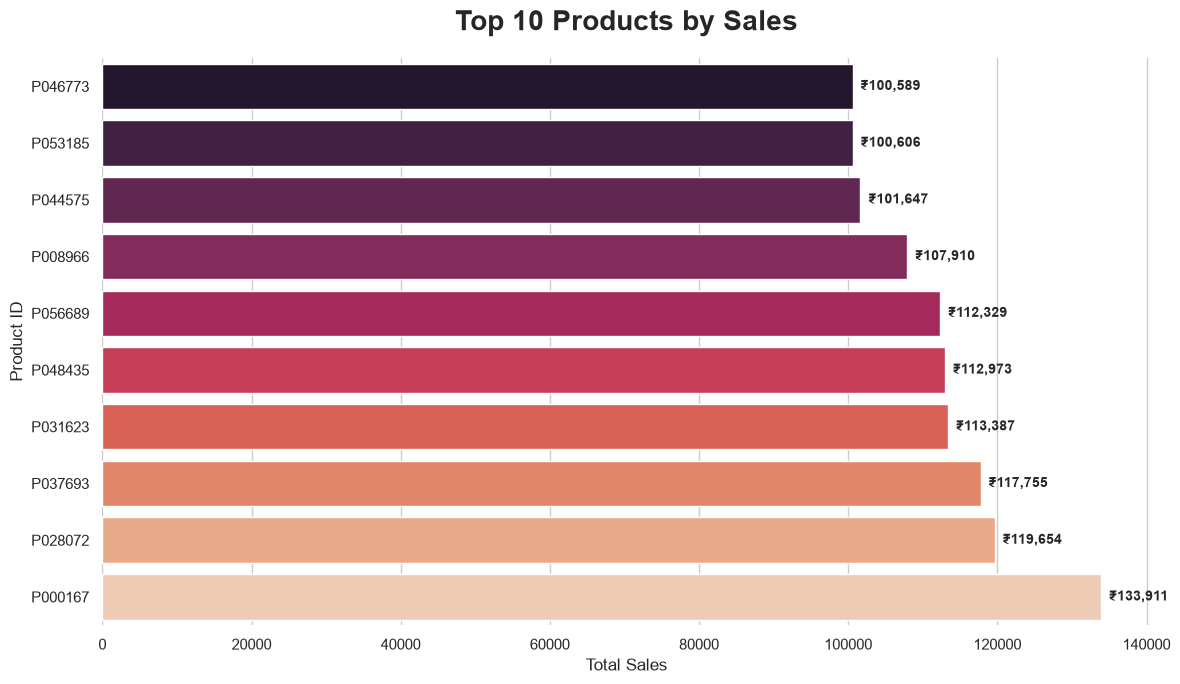

In [79]:
#5. Top 10 Products
top_products = (
    df.groupby("product_id")["total_amount"]
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=top_products.values,
    y=top_products.index.astype(str),
    hue=top_products.index.astype(str),
    palette="rocket",
    legend=False
)

plt.title("Top 10 Products by Sales",
          fontsize=20, fontweight="bold", pad=20)

plt.xlabel("Total Sales", fontsize=12)
plt.ylabel("Product ID", fontsize=12)

for i, value in enumerate(top_products.values):
    ax.text(value, i, f"  ₹{value:,.0f}",
            va="center", fontsize=10, fontweight="bold")

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

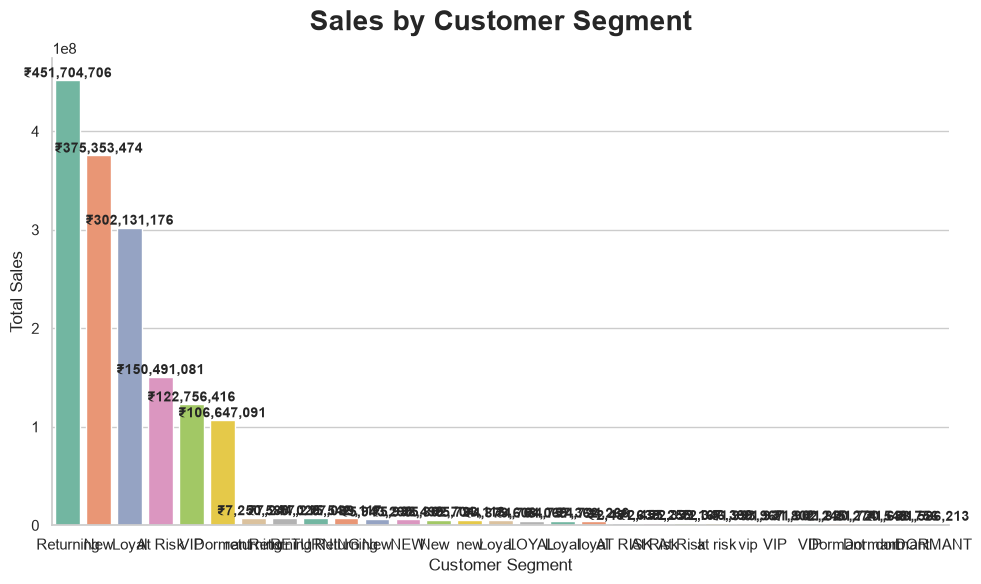

In [80]:
#6. Customer Segment Sales
segment_sales = (
    df.groupby("customer_segment")["total_amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=segment_sales.index,
    y=segment_sales.values,
    hue=segment_sales.index,
    palette="Set2",
    legend=False
)

plt.title("Sales by Customer Segment",
          fontsize=20, fontweight="bold", pad=20)

plt.xlabel("Customer Segment", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)

for i, value in enumerate(segment_sales.values):
    ax.text(i, value, f"₹{value:,.0f}",
            ha="center", va="bottom",
            fontsize=10, fontweight="bold")

sns.despine()
plt.tight_layout()
plt.show()

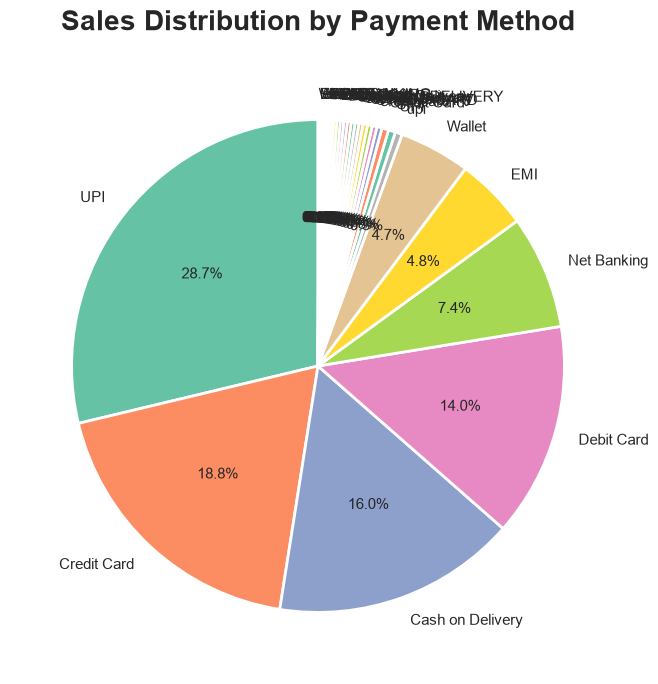

In [81]:
#7. Payment Method Distribution
payment_sales = (
    df.groupby("payment_method")["total_amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 7))

colors = sns.color_palette("Set2", len(payment_sales))

plt.pie(
    payment_sales.values,
    labels=payment_sales.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11}
)

plt.title("Sales Distribution by Payment Method",
          fontsize=20, fontweight="bold", pad=20)

plt.tight_layout()
plt.show()

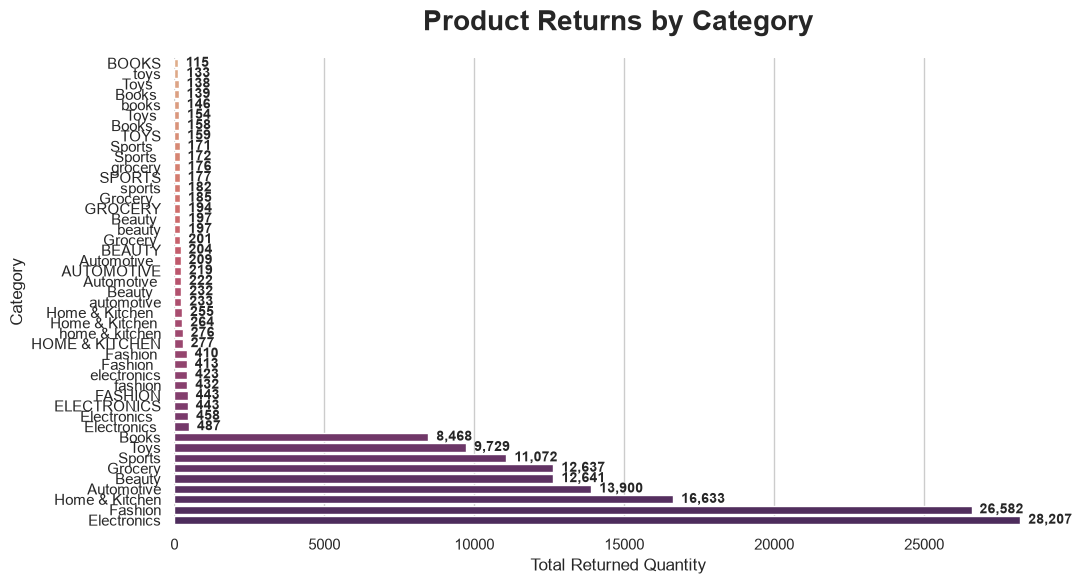

In [82]:
#8. Returns by Category
returns_category = (
    df.groupby("category")["return_qty"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=returns_category.values,
    y=returns_category.index,
    hue=returns_category.index,
    palette="flare",
    legend=False
)

plt.title("Product Returns by Category",
          fontsize=20, fontweight="bold", pad=20)

plt.xlabel("Total Returned Quantity", fontsize=12)
plt.ylabel("Category", fontsize=12)

for i, value in enumerate(returns_category.values):
    ax.text(value, i, f"  {value:,.0f}",
            va="center", fontsize=10, fontweight="bold")

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

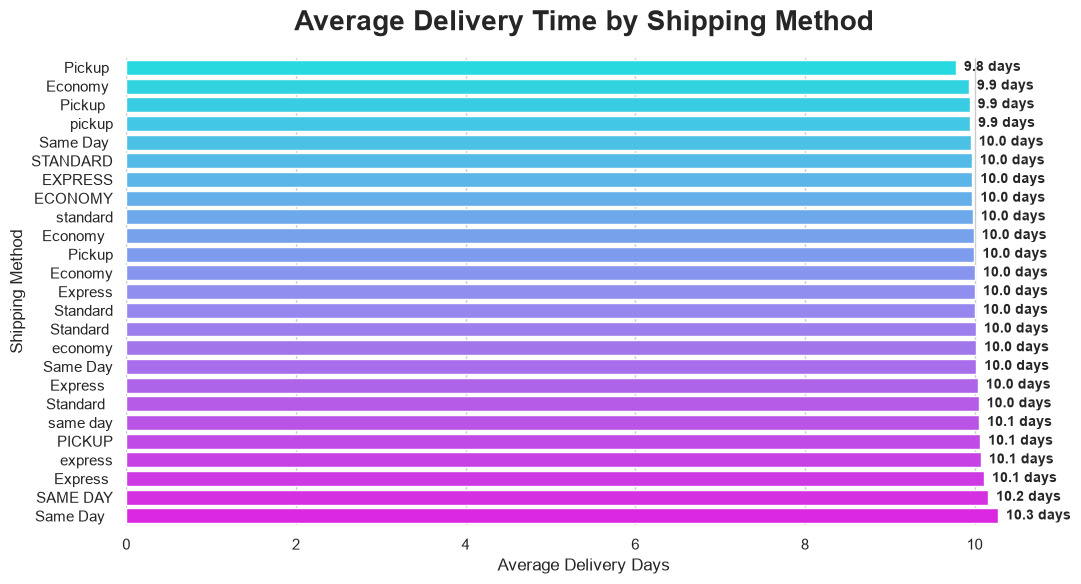

In [83]:
#9. Delivery Performance
delivery = (
    df.groupby("shipping_method")["delivery_days"]
    .mean()
    .sort_values(ascending=True)
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=delivery.values,
    y=delivery.index,
    hue=delivery.index,
    palette="cool",
    legend=False
)

plt.title("Average Delivery Time by Shipping Method",
          fontsize=20, fontweight="bold", pad=20)

plt.xlabel("Average Delivery Days", fontsize=12)
plt.ylabel("Shipping Method", fontsize=12)

for i, value in enumerate(delivery.values):
    ax.text(value, i, f"  {value:.1f} days",
            va="center", fontsize=10, fontweight="bold")

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

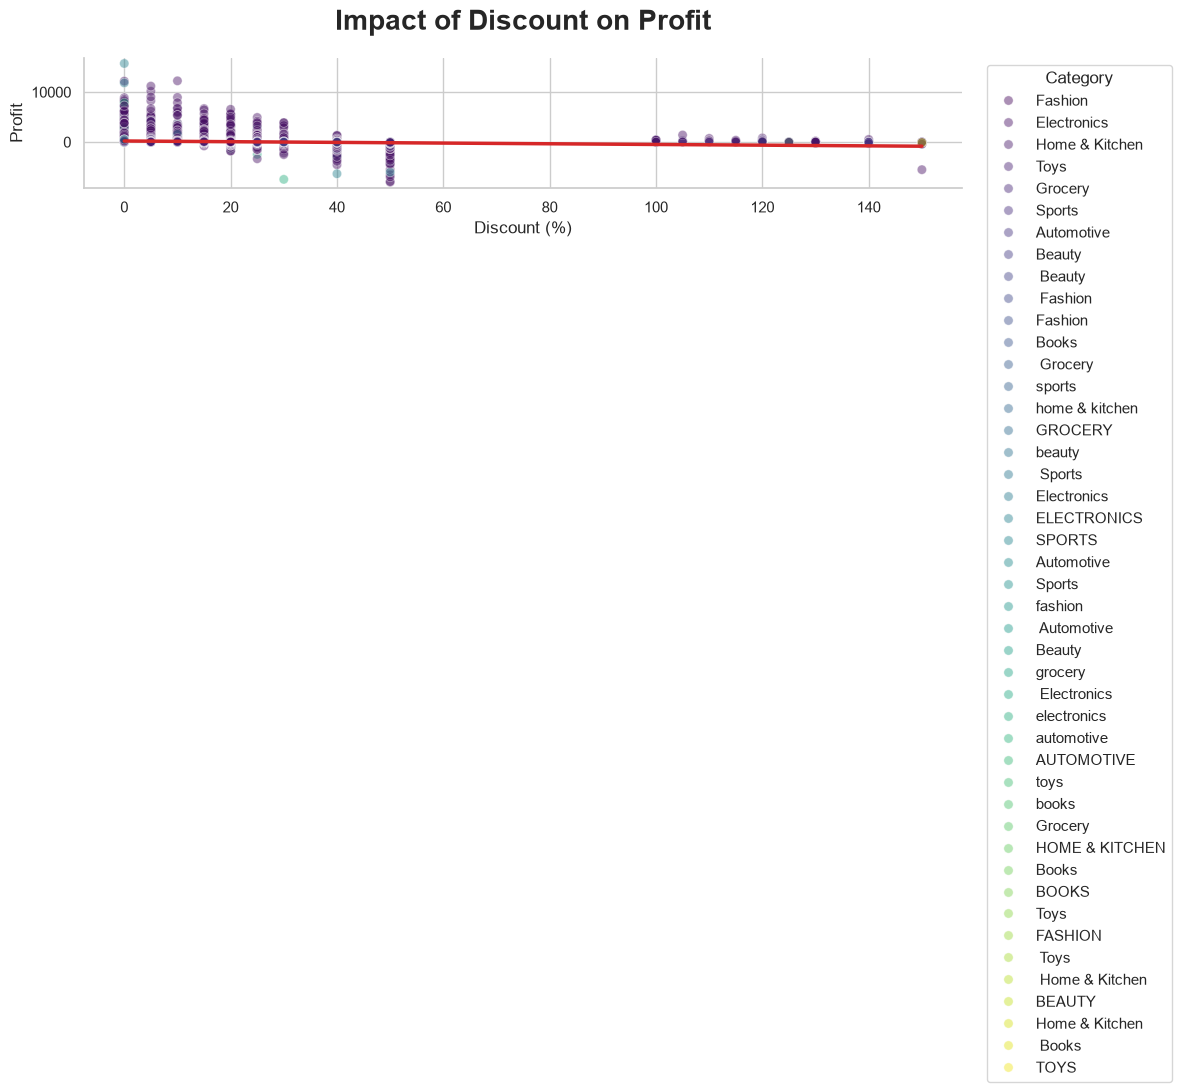

In [84]:
#10. Discount vs Profit
sample_df = df.sample(
    min(100000, len(df)),
    random_state=42
)

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=sample_df,
    x="discount_pct",
    y="profit",
    hue="category",
    palette="viridis",
    alpha=0.45,
    s=45
)

sns.regplot(
    data=sample_df,
    x="discount_pct",
    y="profit",
    scatter=False,
    color="#D62728",
    line_kws={"linewidth": 2.5}
)

plt.title("Impact of Discount on Profit",
          fontsize=20, fontweight="bold", pad=20)

plt.xlabel("Discount (%)", fontsize=12)
plt.ylabel("Profit", fontsize=12)

plt.legend(
    title="Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

sns.despine()
plt.tight_layout()
plt.show()